# Estadística Computacional 2026-2C — Guía 4
## Ejercicios 23 y 24: intervalos de confianza y cobertura

Notebook **para completar en clase**. Donde aparece `@@@@@@` hay que escribir
la línea que falta; el comentario de al lado dice qué tiene que calcular. Todo lo
demas (gráficos, `print`s, chequeos) ya está hecho: si la línea sale bien, el
gráfico y los chequeos de abajo funcionan solos.
| Ej. | Tema | Idea central |
|----|------|--------------|
| **23** | Nivel de confianza vs cobertura | La fracción de intervalos que tapan a $\mu$ es $1-\alpha$; la confianza es una propiedad del **procedimiento** |
| **24** | Los cuatro pivotes | $Z$, $T$, $C_2=n s^2/\sigma^2$, $C_3=(n-1)S^2/\sigma^2$ y los cuatro IC que salen de invertirlos |

> **Convención de cuantiles.** Todos los subíndices de acá son **acumulados**: en
> $z_{0{,}975}=1{,}96$ o $\chi^2_{2;\,0{,}975}=7{,}38$ el número es el área **a
> izquierda**. En código eso es literalmente `stats.norm.ppf(0.975)` y
> `stats.chi2.ppf(0.975, df)`

In [2]:
%pip install numpy
%pip install matplotlib
%pip install scipy

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Paleta con semántica fija (sin rojo/verde, por daltonismo):
#   CUBRE = azul    -> el intervalo tapa el valor verdadero
#   FALLA = naranja -> no lo tapa
#   TEO   = negro   -> curva o valor teórico de referencia
CUBRE, FALLA, TEO = "#2471a3", "#e08a1e", "#111111"
VIOLETA, VERDE = "#8256a8", "#4a9c7d"

rng = np.random.default_rng(2026)   # cada celda vuelve a fijar semilla para correr aislada

  Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.7 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 7.5 MB/s eta 0:00:00
  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 11.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 10.6 MB/s eta 0:00:0000:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 13.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.9 MB/s eta 0:00:00a 0:00:01
Usin

---
# Ejercicio 23

Un fenómeno produce valores con distribución $\text{Normal}(\mu,\sigma^2)$, y cada
medición (por ejemplo, una encuesta chica) es una muestra de **5** valores. Eligiendo
$\mu$ y $\sigma^2$, y repitiendo para niveles $0{,}68$, $0{,}95$ y $0{,}99$:

- **(a)** generar $1000$ muestras; con cada una estimar $\mu$ por $\bar X$ (con
  $\sigma^2$ **conocida**) y calcular el IC de nivel $1-\alpha$;
- **(b)** graficar $\mu$ y los $1000$ intervalos desplegados hacia arriba, "como un
  sánguche de capas". ¿Hay intervalos claramente lejos de $\mu$?
- **(c)** calcular la fracción que incluye al $\mu$ verdadero. ¿Coincide con $1-\alpha$?
  ¿Es compatible con una binomial?
- **(d)** si tuviera una sola muestra (como en la realidad), ¿cuál sería su caso?
- **(e)** ¿dependen las respuestas de que la subyacente sea normal? ¿Y con una Cauchy?

**De dónde sale el intervalo.** No lo copiamos de una fórmula: sale de invertir un
**pivote**, en cuatro pasos (T6 de la guía resuelta).

1. **El pivote.** Con $X_i\sim N(\mu,\sigma^2)$ i.i.d. vale
   $\bar X\sim N(\mu,\sigma^2/n)$, y estandarizando
   $$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}=\frac{\sqrt n(\bar X-\mu)}{\sigma}\sim N(0,1).$$
   Lo importante: su distribución **no depende de $\mu$ ni de nada desconocido**. Por eso
   se le pueden pedir probabilidades.
2. **Pedirle probabilidad $1-\alpha$.** Buscamos $b$ con $P(-b\le Z\le b)=1-\alpha$. Como
   la normal es simétrica, eso reparte $\alpha/2$ en cada cola, y entonces $b$ deja
   $1-\alpha/2$ de área acumulada: $b=\Phi^{-1}(1-\alpha/2)$, que es lo que escribimos
   $z_{1-\alpha/2}$.
3. **Volver a $\bar X$.** Multiplicando la desigualdad por $\sigma/\sqrt n$:
   $$|\bar X-\mu|\le z_{1-\alpha/2}\,\frac{\sigma}{\sqrt n}.$$
4. **Despejar $\mu$.** Es el paso que da el intervalo:
   $$\bar X - z_{1-\alpha/2}\frac{\sigma}{\sqrt n}\ \le\ \mu\ \le\
   \bar X + z_{1-\alpha/2}\frac{\sigma}{\sqrt n}.$$

Lo **aleatorio** son los dos extremos, no $\mu$. El $1-\alpha$ es la probabilidad de que
el intervalo (que se mueve) atrape al $\mu$ (que está fijo).

In [10]:
# ---------------------------------------------------------------- helpers del Ej 23
def ic_media(X, sigma, nivel):
    """IC para mu con sigma CONOCIDA, para cada fila de X (matriz de N x n).

    Devuelve dos vectores de largo N: los extremos izquierdo y derecho.
    """
    n = X.shape[1]
    xb = X.mean(axis=1)                              # media muestral de cada una de las N muestras
    z = stats.norm.ppf(1 - (1 - nivel)/2)    # <-- cuantil con área acumulada 1 - alfa/2
    semiancho = z * sigma/np.sqrt(n)    # <-- semiancho del intervalo
    return xb - semiancho, xb + semiancho


def cobertura(lo, hi, valor):
    """Fracción de intervalos que tapan `valor`, y el vector de booleanos."""
    cubre = (lo <= valor) & (valor <= hi)    # <-- True si el intervalo tapa a `valor`   (pista: ojo: son DOS desigualdades)
    return cubre.mean(), cubre


# --- chequeo de los helpers: con estos números la respuesta se sabe a mano ---
_X = np.array([[9.0, 10.0, 11.0]])          # una sola muestra, media 10
_lo, _hi = ic_media(_X, sigma=3.0, nivel=0.95)
print(f"largo del IC = {_hi[0] - _lo[0]:.4f}   (debe dar 2 * 1.9600 * 3/raiz(3) = 6.7896)")
print(f"semiancho    = {(_hi[0] - _lo[0]) / 2:.4f}   (la mitad: 3.3948)")
assert np.isclose(_hi[0] - _lo[0], 2 * 1.959963985 * 3 / np.sqrt(3)), "revisar ic_media"
assert cobertura(np.array([0.0]), np.array([2.0]), 1.0)[0] == 1.0, "revisar cobertura"
assert cobertura(np.array([0.0]), np.array([2.0]), 5.0)[0] == 0.0, "revisar cobertura"
print("helpers OK")

largo del IC = 6.7895   (debe dar 2 * 1.9600 * 3/raiz(3) = 6.7896)
semiancho    = 3.3948   (la mitad: 3.3948)
helpers OK


## (a) Las 1000 muestras y sus intervalos a los tres niveles

Un detalle que conviene ver: usamos **las mismas** 1000 muestras para los tres niveles.
Cambiar el nivel no cambia las medias muestrales, solo estira o encoge el mismo intervalo
alrededor de cada $\bar X$. Por eso los tres intervalos de una muestra están
**encajados** y la cobertura solo puede **subir** con el nivel.

In [11]:
rng = np.random.default_rng(7)

MU, SIGMA, n, N = 10.0, 2.0, 5, 1000
X = rng.normal(MU, SIGMA, size=(N, n))               # las N muestras, una por fila
niveles = [0.68, 0.95, 0.99]

resultados = {}
print(f"{'nivel':>6} {'z':>7} {'semiancho':>10} {'tapan':>7} {'cobertura':>10} "
      f"{'esperado':>9} {'z de la cuenta':>15}")
for nivel in niveles:
    lo, hi = ic_media(X, SIGMA, nivel)
    frac, cubre = cobertura(lo, hi, MU)
    resultados[nivel] = {"lo": lo, "hi": hi, "cubre": cubre, "frac": frac}
    semiancho = (hi - lo).mean() / 2
    z = semiancho / (SIGMA / np.sqrt(n))             # recuperamos el z usado, desde el propio IC
    sd_bin = np.sqrt(N * nivel * (1 - nivel))        # desvío de Bin(N, 1-alfa)
    print(f"{nivel:>6.2f} {z:>7.3f} {semiancho:>10.4f} "
          f"{cubre.sum():>7d} {frac:>10.4f} {N * nivel:>9.0f} "
          f"{(cubre.sum() - N * nivel) / sd_bin:>+15.2f}")

 nivel       z  semiancho   tapan  cobertura  esperado  z de la cuenta
  0.68   0.994     0.8895     663     0.6630       680           -1.15
  0.95   1.960     1.7530     954     0.9540       950           +0.58
  0.99   2.576     2.3039     995     0.9950       990           +1.59


## (b) El "sánguche de capas"

Cada segmento horizontal es un intervalo; la altura es solo para desplegarlos y no
significa nada. **Naranja = no tapa a $\mu$.** El punto es el $\bar X$ de esa muestra.

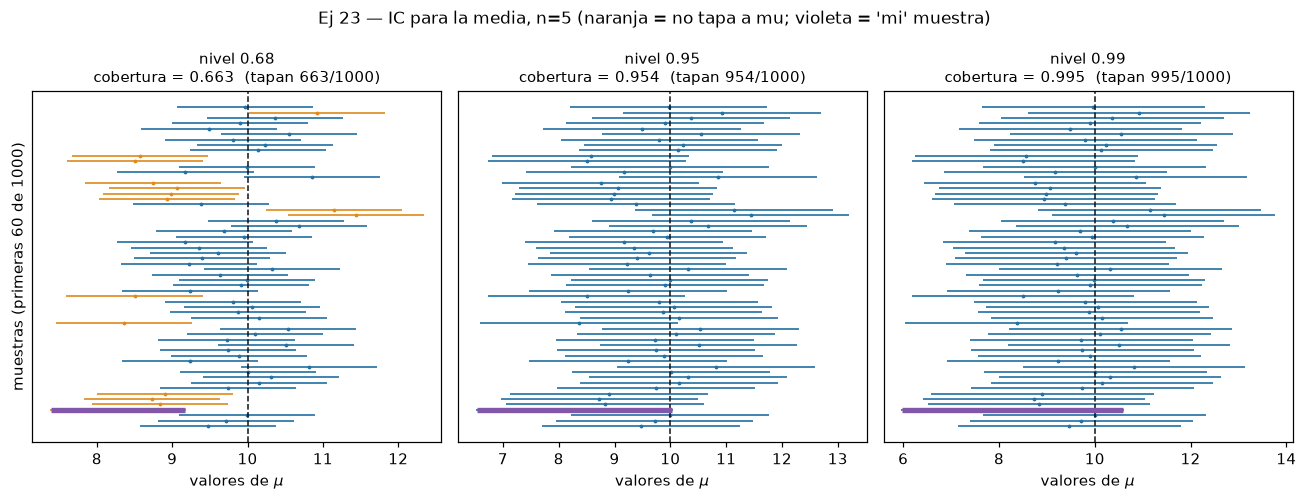

Item (d) — la muestra 3 es la unica que tendrias en la realidad:
  nivel 0.68: (7.392, 9.171)  ->  NO tapa a mu = 10.0
  nivel 0.95: (6.528, 10.034)  ->  SI tapa a mu = 10.0
  nivel 0.99: (5.977, 10.585)  ->  SI tapa a mu = 10.0


In [12]:
MI_MUESTRA = 3        # item (d): la unica muestra que en la realidad uno tendria
K = 60                # cuantos intervalos se dibujan (los calculos usan las N)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, nivel in zip(axes, niveles):
    r = resultados[nivel]
    for j in range(K):
        color = CUBRE if r["cubre"][j] else FALLA
        ax.plot([r["lo"][j], r["hi"][j]], [j, j], color=color, lw=1.3, alpha=0.85)
        ax.plot((r["lo"][j] + r["hi"][j]) / 2, j, ".", color=color, ms=3)
    # la muestra del item (d), resaltada
    ax.plot([r["lo"][MI_MUESTRA], r["hi"][MI_MUESTRA]], [MI_MUESTRA] * 2,
            color=VIOLETA, lw=3.5, solid_capstyle="butt", zorder=5)
    ax.axvline(MU, color=TEO, ls="--", lw=1)
    ax.set_title(f"nivel {nivel:.2f}\ncobertura = {r['frac']:.3f}  "
                 f"(tapan {r['cubre'].sum()}/{N})", fontsize=10)
    ax.set_xlabel(r"valores de $\mu$")
    ax.set_yticks([])
axes[0].set_ylabel(f"muestras (primeras {K} de {N})")
fig.suptitle(f"Ej 23 — IC para la media, n={n} (naranja = no tapa a mu; "
             f"violeta = 'mi' muestra)", fontsize=11)
fig.tight_layout()
plt.show()

print("Item (d) — la muestra", MI_MUESTRA, "es la unica que tendrias en la realidad:")
for nivel in niveles:
    r = resultados[nivel]
    tapa = "SI tapa" if r["cubre"][MI_MUESTRA] else "NO tapa"
    print(f"  nivel {nivel:.2f}: ({r['lo'][MI_MUESTRA]:.3f}, {r['hi'][MI_MUESTRA]:.3f})"
          f"  ->  {tapa} a mu = {MU}")

**Para responder (b) y (d).**

- ¿Hay intervalos claramente lejos del valor subyacente $\mu$? ¿Tienen algo de distinto de
  los otros, más allá de haber "fallado"? ¿Qué fracción se espera que falle?
- ¿Por qué al subir el nivel hay menos naranjas? ¿Qué se paga a cambio?
- Cambiá `MI_MUESTRA` y volvé a correr. Si tuvieras **una sola** muestra (lo que pasa en la
  realidad), ¿podrías decidir si tu intervalo tapa a $\mu$? ¿Qué te haría falta saber?
  Entonces, ¿qué significa exactamente "confianza del 95 %"?

## (c) ¿Es compatible con una binomial?

Cada muestra tapa o no tapa a $\mu$, con la misma probabilidad $p$ y de forma
independiente de las demás: son $N$ ensayos Bernoulli. Entonces

$$\#\{\text{intervalos que tapan}\}\sim\text{Bin}(N,p),\qquad p=1-\alpha\ \text{si el
método es correcto},$$

con desvío $\sqrt{N\alpha(1-\alpha)}$ — con $N=1000$ y nivel $0{,}95$ eso es $6{,}9$.
Para verlo no alcanza **una** cuenta: repetimos todo el experimento $R$ veces y comparamos
el histograma de las $R$ cuentas contra la función de probabilidad de la binomial.

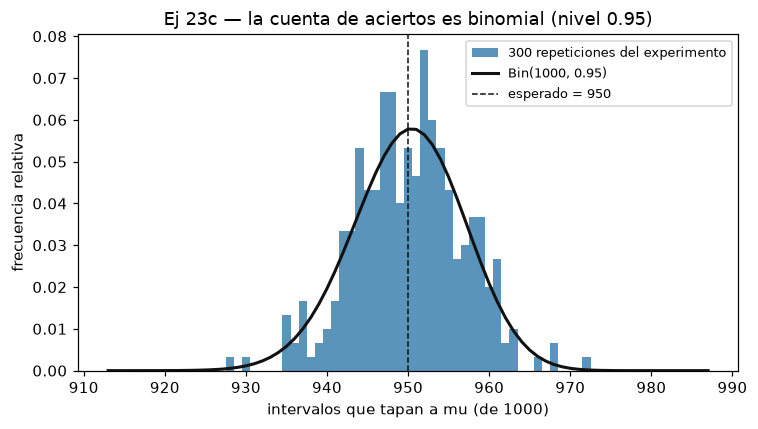

cobertura real estimada  = 0.9502   (nominal 0.95)
desvío de las R cuentas  = 6.72   (binomial predice 6.89)
rango de las cuentas     = 928 a 972


In [14]:
rng = np.random.default_rng(1234)

R, NIVEL_C = 300, 0.95
cuentas = np.empty(R, dtype=int)
for r_i in range(R):
    Xr = rng.normal(MU, SIGMA, size=(N, n))
    lo_r, hi_r = ic_media(Xr, SIGMA, NIVEL_C)
    cuentas[r_i] = cobertura(lo_r, hi_r, MU)[1].sum()   # <-- cuántos intervalos tapan a MU   (pista: cobertura(...) devuelve (fraccion, booleanos))

sd_bin = np.sqrt(N * NIVEL_C * (1 - NIVEL_C))
fig, ax = plt.subplots(figsize=(7, 4))
bordes = np.arange(cuentas.min() - 0.5, cuentas.max() + 1.5)
ax.hist(cuentas, bins=bordes, density=True, color=CUBRE, alpha=0.75,
        label=f"{R} repeticiones del experimento")
kk = np.arange(cuentas.min() - 15, cuentas.max() + 16)
ax.plot(kk, stats.binom.pmf(kk, N, NIVEL_C), color=TEO, lw=2,
        label=f"Bin({N}, {NIVEL_C})")
ax.axvline(N * NIVEL_C, color=TEO, ls="--", lw=1, label=f"esperado = {N * NIVEL_C:.0f}")
ax.set_xlabel(f"intervalos que tapan a mu (de {N})")
ax.set_ylabel("frecuencia relativa")
ax.set_title(f"Ej 23c — la cuenta de aciertos es binomial (nivel {NIVEL_C})")
ax.legend(fontsize=8.5)
fig.tight_layout()
plt.show()

print(f"cobertura real estimada  = {cuentas.mean() / N:.4f}   (nominal {NIVEL_C})")
print(f"desvío de las R cuentas  = {cuentas.std():.2f}   (binomial predice {sd_bin:.2f})")
print(f"rango de las cuentas     = {cuentas.min()} a {cuentas.max()}")

**Para responder (c).** ¿El desvío empírico de las $R$ cuentas coincide con el
$\sqrt{N\alpha(1-\alpha)}$ que predice la binomial? Entonces, ¿las diferencias respecto de
$N(1-\alpha)$ son un defecto del método o algo esperable?

Y una pregunta más difícil, que se contesta en el ítem (e): si la subyacente **no** fuera
normal, ¿la cuenta seguiría siendo binomial? ¿Qué parte de la binomial cambiaría?

## (e) ¿Depende de que la subyacente sea normal?

Probamos con cuatro subyacentes, todas con la **misma** media $\mu$ y el mismo $\sigma$
que usa la fórmula. La Cauchy es el caso interesante: **no tiene media ni varianza**, así
que el $\sigma$ que le pasamos no es un desvío, es apenas un parámetro de escala — el
número que el método va a *creer* que es el desvío.

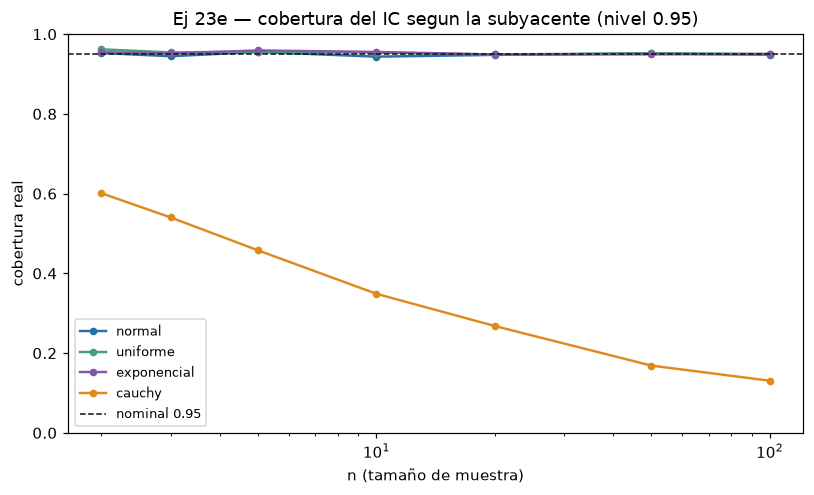

    n   simulada  formula exacta
    2     0.6010          0.6021
    3     0.5402          0.5392
    5     0.4578          0.4582
   10     0.3488          0.3532
   20     0.2680          0.2630
   50     0.1688          0.1721
  100     0.1308          0.1232


In [24]:
def generar(kind, mu, sigma, size, rng):
    """Muestras con media mu y desvío sigma (salvo la Cauchy, que no tiene ninguno)."""
    if kind == "normal":
        return rng.normal(mu, sigma, size)
    if kind == "uniforme":                       # Var = (2a)^2/12 = sigma^2  =>  a = sigma*raiz(3)
        a = sigma * np.sqrt(3.0)
        return rng.uniform(mu - a, mu + a, size)
    if kind == "exponencial":                    # Exp(escala=sigma) corrida: media mu, desvío sigma
        return mu - sigma + rng.exponential(sigma, size)
    if kind == "cauchy":                         # sin media ni varianza; sigma = escala
        return mu + sigma * rng.standard_cauchy(size)
    raise ValueError(kind)


NIVEL_E, REPS = 0.95, 5000
ns = [2, 3, 5, 10, 20, 50, 100]
colores = {"normal": CUBRE, "uniforme": VERDE, "exponencial": VIOLETA, "cauchy": FALLA}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for kind, color in colores.items():
    rng = np.random.default_rng(99)
    cobs = []
    for nn in ns:
        Xe = generar(kind, MU, SIGMA, (REPS, nn), rng)
        lo_e, hi_e = ic_media(Xe, SIGMA, NIVEL_E)
        cobs.append(cobertura(lo_e, hi_e, MU)[0])
    ax.plot(ns, cobs, "o-", color=color, label=kind, lw=1.6, ms=4)
    if kind == "cauchy":
        cob_cauchy = dict(zip(ns, cobs))
ax.axhline(NIVEL_E, color=TEO, ls="--", lw=1, label=f"nominal {NIVEL_E}")
ax.set_xscale("log"); ax.set_ylim(0, 1)
ax.set_xlabel("n (tamaño de muestra)"); ax.set_ylabel("cobertura real")
ax.set_title(f"Ej 23e — cobertura del IC segun la subyacente (nivel {NIVEL_E})")
ax.legend(fontsize=8.5)
fig.tight_layout()
plt.show()

# La Cauchy tiene cobertura EXACTA calculable a mano (ver la celda de texto de abajo),
# porque el promedio de n Cauchy de escala sigma es otra vez Cauchy de escala sigma.
z_e = stats.norm.ppf(1 - (1 - NIVEL_E) / 2)
print(f"{'n':>5} {'simulada':>10} {'formula exacta':>15}")
for nn in ns:
    teo = (2 / np.pi) * np.arctan(z_e / np.sqrt(nn))   # <-- cobertura exacta de la Cauchy   (googleable)
    print(f"{nn:>5} {cob_cauchy[nn]:>10.4f} {teo:>15.4f}")
    # tolerancia = 4 errores estandar de Monte Carlo, raiz(p(1-p)/REPS): escala con REPS
    tol = 4 * np.sqrt(teo * (1 - teo) / REPS)
    assert abs(teo - cob_cauchy[nn]) < tol, "la formula y la simulacion no coinciden"

**Para responder (e).**

- ¿Cuáles de las cuatro subyacentes dan cobertura $\approx 1-\alpha$? Si la distribución no
  es normal, ¿qué hipótesis del desarrollo teórico se está usando? (Pista: $\bar X$.)
- ¿Cuál es la más rebelde de las tres "buenas", y por qué? ¿Se arregla subiendo $n$?
- La **Cauchy**: ¿qué le pasa a su cobertura al aumentar $n$? Es lo contrario de lo
  esperable, así que vale la pena entender por qué. ¿Qué le pasa a $\bar X$ de $n$ Cauchy
  (Guía 3)? ¿Y qué le pasa al ancho del intervalo? Con esas dos cosas se deduce la fórmula
  exacta, que es el blanco de la celda de arriba.

---
# Ejercicio 24

Con un generador $\text{Normal}(\mu,\sigma^2)$ de $\mu=10$ y $\sigma=2$, generar $1000$
muestras $\{X_1,X_2,X_3\}$ de tamaño **3**. Con

$$S^2=\frac{1}{n-1}\sum(X_i-\bar X)^2\ (\mu\ \text{desconocida}),\qquad
s^2=\frac{1}{n}\sum(X_i-\mu)^2\ (\mu\ \text{conocida; es el EMV}),$$

- **(a)** calcular los cuatro pivotes y hacer un histograma **normalizado** de cada uno,
  superponiendo su densidad teórica;
- **(b)** armar los cuatro IC de nivel $95\%$ y contar cuántos tapan el valor verdadero;
- **(c)** las cuentas dan $\approx 95\%$ pero no exactamente. ¿Son compatibles con una
  binomial?

| | pivote | distribución | por qué esos grados de libertad |
|---|---|---|---|
| I | $Z=\sqrt n(\bar X-\mu)/\sigma$ | $N(0,1)$ | combinación lineal de normales |
| II | $T=\sqrt n(\bar X-\mu)/S$ | $t_{n-1}$ | $Z$ dividido por $\sqrt{S^2/\sigma^2}$, independiente de él |
| III | $C_2=n\,s^2/\sigma^2$ | $\chi^2_{n}$ | suma de $n$ normales estándar al cuadrado |
| IV | $C_3=(n-1)S^2/\sigma^2$ | $\chi^2_{n-1}$ | centrar en $\bar X$ **consume un grado** |

El punto fino es la diferencia entre III y IV. $s^2$ usa el $\mu$ **verdadero**, así que
los $n$ sumandos $(X_i-\mu)/\sigma$ son normales estándar independientes: $n$ grados.
$S^2$ usa $\bar X$, que se estimó con **los mismos datos**, y eso impone la restricción
$\sum(X_i-\bar X)=0$: quedan $n-1$ libres.

In [ ]:
def pivotes(X, mu, sigma):
    n = X.shape[1]
    xb = X.mean(axis=1)
    SS_xb = @@@@@@    # <-- suma de (Xi - Xbarra)^2 en cada fila
    SS_mu = @@@@@@    # <-- suma de (Xi - mu)^2 en cada fila
    S2, s2 = SS_xb / (n - 1), SS_mu / n
    Z = @@@@@@    # <-- el pivote Z
    T = @@@@@@    # <-- el pivote T
    C2 = @@@@@@    # <-- el pivote C2
    C3 = @@@@@@    # <-- el pivote C3
    return dict(xb=xb, SS_xb=SS_xb, SS_mu=SS_mu, S2=S2, s2=s2, Z=Z, T=T, C2=C2, C3=C3)


rng = np.random.default_rng(2026)      # con esta semilla se reproduce la tabla de la guia

MU24, SG24, n24, N24 = 10.0, 2.0, 3, 1000
X24 = rng.normal(MU24, SG24, size=(N24, n24))
P = pivotes(X24, MU24, SG24)

# chequeos: las medias de C2 y C3 tienen que dar los grados de libertad (n y n-1)
print(f"media de Z  = {P['Z'].mean():+.3f}   (teorica 0)")
print(f"desvio de Z = {P['Z'].std(ddof=1):.3f}   (teorico 1)")
print(f"media de C2 = {P['C2'].mean():.3f}   (teorica n   = {n24})")
print(f"media de C3 = {P['C3'].mean():.3f}   (teorica n-1 = {n24 - 1})")
# tolerancia = 4 desvios del promedio de N24 chi2: sd(media) = raiz(2*gl/N)
assert abs(P["C2"].mean() - n24) < 4 * np.sqrt(2 * n24 / N24), \
    "C2 no tiene media n: revisar los grados de libertad"
assert abs(P["C3"].mean() - (n24 - 1)) < 4 * np.sqrt(2 * (n24 - 1) / N24), \
    "C3 no tiene media n-1: revisar los grados de libertad"

## (a) Los cuatro histogramas contra su densidad exacta

**Cuidado con la normalización.** `plt.hist(..., density=True, range=(a,b))` normaliza
usando **solo los puntos que caen dentro del rango**, así que las barras quedan infladas
respecto de la densidad teórica (con $t_2$ en $(-8,8)$ el sesgo es $1{,}6\%$; con $t_1$,
$8{,}7\%$). Acá dividimos a mano por $N\cdot(\text{ancho de bin})$, que es lo correcto, y
reportamos qué fracción se fue del rango.

In [ ]:
def histograma_vs_densidad(ax, datos, dist, rango, titulo, color, bins=40):
    """Histograma normalizado a mano (NO con density=True, que sesga si se recorta)."""
    cnt, bordes = np.histogram(datos, bins=bins, range=rango)
    ancho = bordes[1] - bordes[0]
    altura = @@@@@@    # <-- densidad empirica (ver la celda de texto de arriba)
    ax.bar(bordes[:-1], altura, width=ancho, align="edge", color=color, alpha=0.6)
    # arrancamos un pelo adentro: la chi2 con 1 g.l. tiene densidad infinita en 0
    eps = (rango[1] - rango[0]) * 1e-4
    xx = np.linspace(rango[0] + eps, rango[1] - eps, 400)
    ax.plot(xx, dist.pdf(xx), color=TEO, lw=1.7)
    fuera = np.mean((datos < rango[0]) | (datos > rango[1]))
    ax.set_title(f"{titulo}\n({fuera:.1%} fuera del rango)", fontsize=9.5)
    ax.set_xlim(*rango)


t_d, c2_d, c3_d = stats.t(df=n24 - 1), stats.chi2(df=n24), stats.chi2(df=n24 - 1)
rT = min(12.0, t_d.ppf(0.995))

fig, axes = plt.subplots(2, 2, figsize=(10, 6.8))
histograma_vs_densidad(axes[0, 0], P["Z"], stats.norm(), (-4, 4),
                       r"$Z=\sqrt{n}(\bar X-\mu)/\sigma\sim N(0,1)$", CUBRE)
histograma_vs_densidad(axes[0, 1], P["T"], t_d, (-rT, rT),
                       rf"$T=\sqrt{{n}}(\bar X-\mu)/S\sim t_{{{n24 - 1}}}$", FALLA)
histograma_vs_densidad(axes[1, 0], P["C2"], c2_d, (0, c2_d.ppf(0.995)),
                       rf"$C_2=n\,s^2/\sigma^2\sim\chi^2_{{{n24}}}$", VIOLETA)
histograma_vs_densidad(axes[1, 1], P["C3"], c3_d, (0, c3_d.ppf(0.995)),
                       rf"$C_3=(n-1)S^2/\sigma^2\sim\chi^2_{{{n24 - 1}}}$", VERDE)
for ax in axes.flat:
    ax.set_ylabel("densidad")
fig.suptitle(f"Ej 24a — los cuatro pivotes y su distribucion exacta "
             f"({N24} muestras de n={n24})", fontsize=11)
fig.tight_layout()
plt.show()

**Para responder (a).**

- Comparando los paneles de $Z$ y de $T$: ¿cuál tiene colas más pesadas, y por qué? ¿Qué
  tiene de particular la $t_2$? (Mirá qué pasa con su varianza.) ¿Qué consecuencia práctica
  tiene eso para el intervalo de confianza de la media?
- $C_2$ y $C_3$ son las dos de la varianza. ¿En qué se diferencian sus histogramas? ¿Cuánto
  dan sus medias y qué relación tiene eso con los grados de libertad?
- ¿Por qué $s^2$ tiene $n$ grados de libertad y $S^2$ solo $n-1$? Lo decide **qué centro**
  usa cada uno.
- Subí `n24` a 10 o 30 y volvé a correr: ¿a qué se parecen los cuatro histogramas?

## (b) Los cuatro intervalos, invirtiendo cada pivote

$$\text{I)}\ \ \bar X \pm z_{1-\alpha/2}\frac{\sigma}{\sqrt n}
\qquad\qquad
\text{II)}\ \ \bar X \pm t_{n-1;\,1-\alpha/2}\frac{S}{\sqrt n}$$

Para III) y IV) hay que **despejar $\sigma^2$** a partir del pivote. Se arranca de

$$\chi^2_{n;\,\alpha/2}\ \le\ \frac{\sum(X_i-\mu)^2}{\sigma^2}\ \le\ \chi^2_{n;\,1-\alpha/2}$$

(y lo análogo con $\sum(X_i-\bar X)^2$ y $n-1$ grados para IV). Para dejar $\sigma^2$ solo
hay que **tomar recíprocos**, y eso **da vuelta las desigualdades** — ahí está el cuidado.
Es el error más común de todo el práctico, así que la celda siguiente tiene un `assert`
que lo detecta.

In [ ]:
def ic_varianza(SS, df, nivel):
    """IC para sigma^2 a partir de SS/sigma^2 ~ chi2_df.  Ojo con el orden."""
    a2 = (1 - nivel) / 2                             # area de cada cola
    lo = @@@@@@    # <-- extremo IZQUIERDO
    hi = @@@@@@    # <-- extremo derecho
    assert np.all(lo < hi), "INTERVALO INVERTIDO: revisar el orden de los cuantiles"
    return lo, hi


NIVEL24 = 0.95
a2_24 = (1 - NIVEL24) / 2
z24 = stats.norm.ppf(1 - a2_24)
t24 = @@@@@@    # <-- cuantil de la t para el IC de la media

lo1, hi1 = ic_media(X24, SG24, NIVEL24)                                  # I)  mu, sigma conocida
semi2 = t24 * np.sqrt(P["S2"] / n24)
lo2, hi2 = P["xb"] - semi2, P["xb"] + semi2                              # II) mu, sigma desconocida
lo3, hi3 = ic_varianza(P["SS_mu"], n24, NIVEL24)                         # III) sigma^2, mu conocida
lo4, hi4 = ic_varianza(P["SS_xb"], n24 - 1, NIVEL24)                     # IV)  sigma^2, mu desconocida

casos = [("I)   mu, sigma^2 conocida   ", "Z ", lo1, hi1, MU24),
         ("II)  mu, sigma^2 desconocida", "T ", lo2, hi2, MU24),
         ("III) sigma^2, mu conocida   ", "C2", lo3, hi3, SG24 ** 2),
         ("IV)  sigma^2, mu desconocida", "C3", lo4, hi4, SG24 ** 2)]

sd_bin24 = np.sqrt(N24 * NIVEL24 * (1 - NIVEL24))
cuentas24 = []
print(f"{'IC':<30}{'piv':<5}{'tapan':>7}{'cobertura':>11}{'largo medio':>13}{'z':>8}")
for etiq, piv, lo, hi, objetivo in casos:
    c = cobertura(lo, hi, objetivo)[1].sum()
    cuentas24.append(int(c))
    print(f"{etiq:<30}{piv:<5}{c:>7d}{c / N24:>11.4f}"
          f"{(hi - lo).mean():>13.3f}{(c - N24 * NIVEL24) / sd_bin24:>+8.2f}")

print(f"\nsd de Bin({N24}, {NIVEL24}) = {sd_bin24:.2f}   -> esperado {N24 * NIVEL24:.0f} aciertos")
if (n24, N24, NIVEL24) == (3, 1000, 0.95):      # el caso del enunciado
    assert tuple(cuentas24) == (927, 943, 946, 956), \
        f"con semilla 2026 la guia da (927, 943, 946, 956), salio {tuple(cuentas24)}"
    print("las cuatro cuentas reproducen la tabla de la guia resuelta")

# El IC con sigma desconocida es mas ancho, pero OJO con cuanto:
ratio_cuantiles = t24 / z24
ratio_largos = (hi2 - lo2).mean() / (hi1 - lo1).mean()
print(f"\ncociente de CUANTILES   t/z            = {ratio_cuantiles:.3f}")
print(f"cociente de LARGOS MEDIOS  II / I      = {ratio_largos:.3f}")
print(f"y el motivo: E[S]/sigma = {np.sqrt(P['S2']).mean() / SG24:.4f}  (S sale mas chica que sigma)")

**Para responder (b).**

- Las cuatro cuentas rondan $950$. ¿Por qué tenía que pasar eso incluso con $n=3$, que es
  ridículamente chico? (Pensá en qué distribución tiene cada pivote: ¿exacta o aproximada?)
- Mirá la columna `largo medio`. Los IC I) y II) estiman lo mismo con la misma cobertura:
  ¿cuál es más largo y por qué? ¿Qué se está pagando?
- La celda imprime dos cocientes distintos, el de **cuantiles** ($t/z$) y el de **largos
  medios**. Dan diferente. ¿Por qué? (Pista: ¿qué usa el largo del II), $\sigma$ o $S$?)
  ¿En qué caso coincidirían?

## (c) ¿Son compatibles con una binomial las fluctuaciones?

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
kk = np.arange(900, 990)
ax.plot(kk, stats.binom.pmf(kk, N24, NIVEL24), color=TEO, lw=2,
        label=f"Bin({N24}, {NIVEL24})")
ax.axvline(N24 * NIVEL24, color=TEO, ls="--", lw=1, label="esperado = 950")
ax.axvspan(N24 * NIVEL24 - 2 * sd_bin24, N24 * NIVEL24 + 2 * sd_bin24,
           color=TEO, alpha=0.08, label="+-2 desvios")
for (etiq, piv, *_), c, col in zip(casos, cuentas24,
                                   [CUBRE, FALLA, VIOLETA, VERDE]):
    ax.plot([c, c], [0, stats.binom.pmf(c, N24, NIVEL24)], color=col, lw=2.5)
    ax.plot(c, stats.binom.pmf(c, N24, NIVEL24), "o", color=col, ms=7,
            label=f"{piv}: {c}")
ax.set_xlabel("intervalos que tapan el valor verdadero (de 1000)")
ax.set_ylabel("probabilidad")
ax.set_title("Ej 24c — las cuatro cuentas contra la binomial")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

print("z de cada cuenta:", [float(round((c - 950) / sd_bin24, 2)) for c in cuentas24])
print(f"P(Bin(1000, 0.95) <= 927) = {stats.binom.cdf(927, 1000, 0.95):.4f}")

# ¿el 927 es mala suerte o una formula mal puesta?  Se contesta repitiendo.
cuentas_Z = []
rng_c = np.random.default_rng(555)
for _ in range(200):
    Xc = rng_c.normal(MU24, SG24, size=(N24, n24))
    loc, hic = ic_media(Xc, SG24, NIVEL24)
    cuentas_Z.append(cobertura(loc, hic, MU24)[1].sum())
cuentas_Z = np.array(cuentas_Z)
print(f"\nrepitiendo 200 veces el IC I): media {cuentas_Z.mean():.1f}, "
      f"desvio {cuentas_Z.std():.1f} (binomial predice {sd_bin24:.1f})")
print(f"  -> el 927 fue mala suerte de esa semilla, no un error de la formula")

**Para responder (c).**

- Tres de las cuatro cuentas están a menos de un desvío del esperado. La cuarta (la de $Z$)
  está a $-3{,}34$. ¿Eso prueba que el IC I) esté mal construido? ¿Cómo lo decidirías?
  La última celda hace exactamente ese experimento: interpretá su salida.
- ¿Por qué mirar **cuatro** intervalos a la vez hace más probable ver uno "raro"? (Es el
  tema de la Guía 5.)
- Las cuatro cuentas salen de las **mismas** muestras. ¿Son independientes entre sí?
  ¿Se pueden combinar sus $p$-valores como si fueran cuatro experimentos distintos?